In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.datasets import get_rdataset
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [ ]:
data=get_rdataset("AirPassengers").data
data["Month"]=pd.date_range(
    start="1949-01-01",
    periods=len(data),
    freq="MS"
)

data.set_index("Month",inplace=True)
ts=data["value"]
print("first 5 records")
print(ts.head())

first 5 records
Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: value, dtype: int64


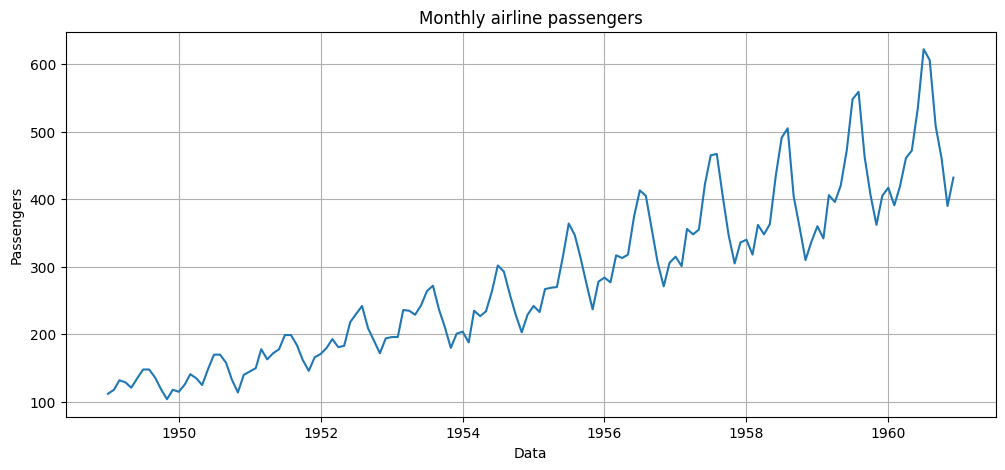

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(ts)
plt.title("Monthly airline passengers")
plt.xlabel("Data")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

In [ ]:
print("\nADF Test: Original Series")
result=adfuller(ts)
print("ADF p-value:",result[1])
if result[1]<0.05:
  print("Series is stationary")
else:
  print("Series is not Stationary")


ADF Test: Original Series
ADF p-value: 0.9918802434376411
Series is not Stationary


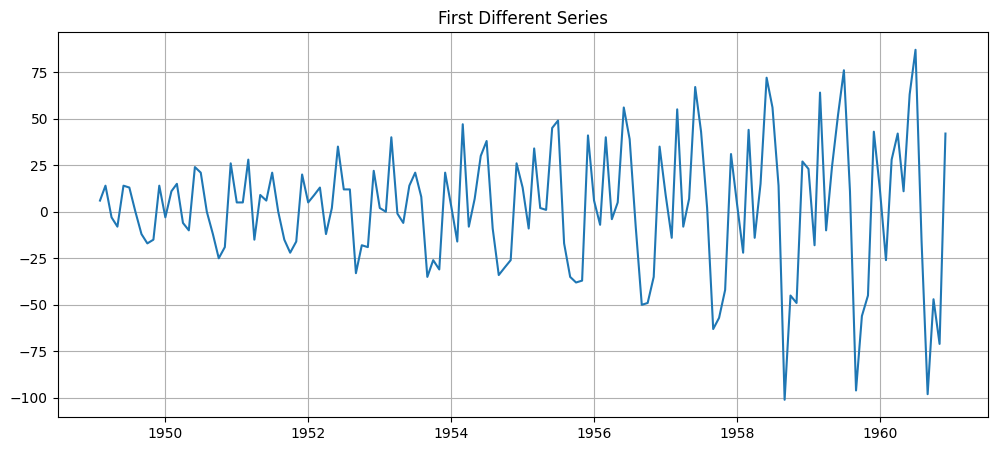


ADF Test: First Different
ADF p-values: 0.05421329028382552
Series is not stationary


In [ ]:
ts_diff=ts.diff().dropna()
plt.figure(figsize=(12,5))
plt.plot(ts_diff)
plt.title("First Different Series")
plt.grid(True)
plt.show()
print("\nADF Test: First Different")
result=adfuller(ts_diff)
print("ADF p-values:",result[1])

if result[1]<0.05:
  print("Series is stationary")
else:
  print("Series is not stationary")

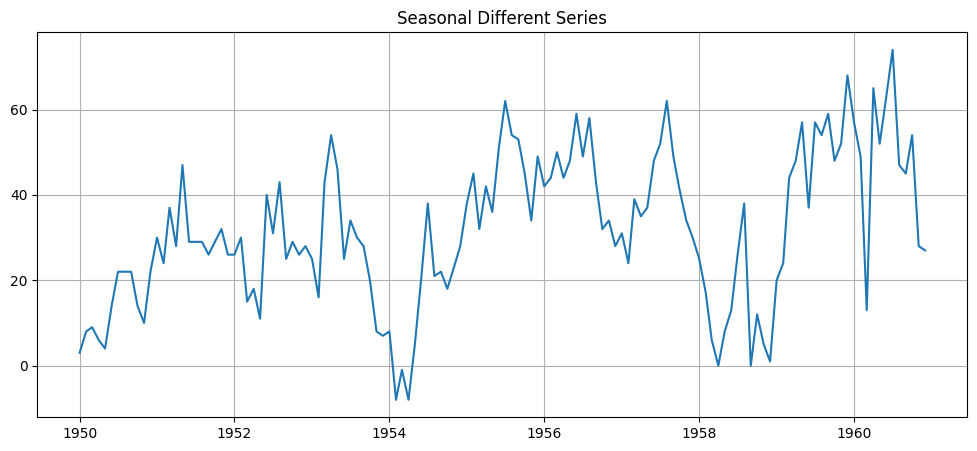


ADF Test: Seasonal Different
ADF p-values: 0.011551493085514952
series is stationary


In [ ]:
s=12
ts_seasonal_diff=ts.diff(12).dropna()
plt.figure(figsize=(12,5))
plt.plot(ts_seasonal_diff)
plt.title("Seasonal Different Series")
plt.grid(True)
plt.show()
print("\nADF Test: Seasonal Different")
result=adfuller(ts_seasonal_diff)
print("ADF p-values:",result[1])

if result[1]<0.05:
  print("series is stationary")
else:
  print("series is not stationary")

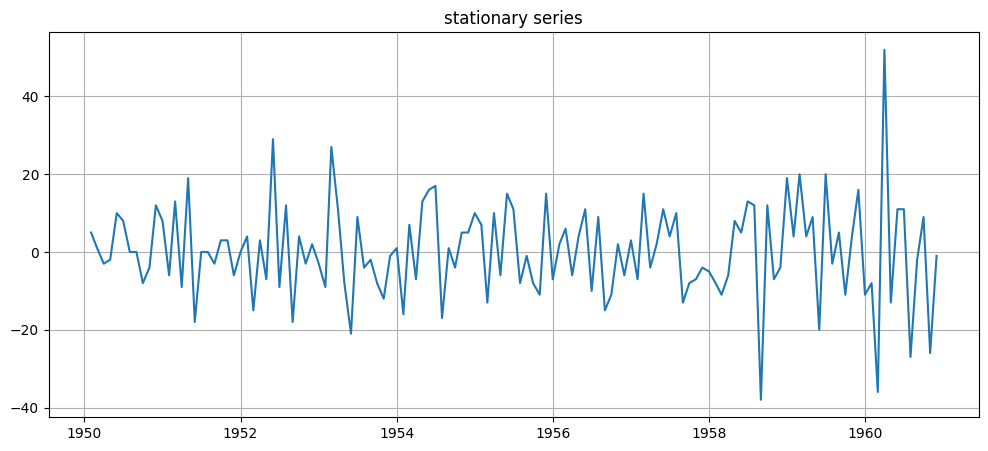


ADF Test: Stationary Series
ADF p-values: 1.856511600123444e-28
Stationary


In [ ]:
stationary_series=ts.diff().diff(12).dropna()
plt.figure(figsize=(12,5))
plt.plot(stationary_series)
plt.title("stationary series")
plt.grid(True)
plt.show()
print("\nADF Test: Stationary Series")
result=adfuller(stationary_series)
print("ADF p-values:",result[1])

if result[1]<0.05:
  print("Stationary")
else:
  print("Non-Stationary")

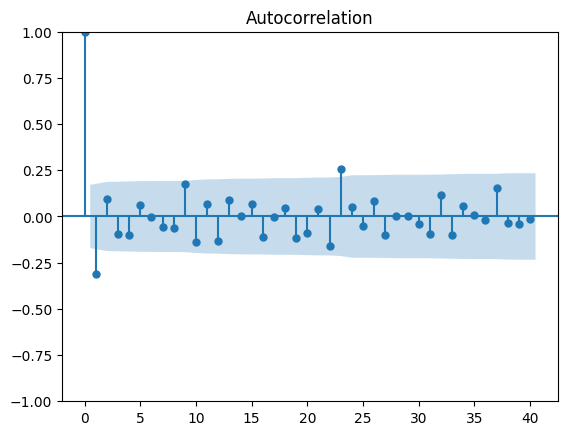

In [ ]:
plot_acf(
    stationary_series,
    lags=40
)
plt.show()

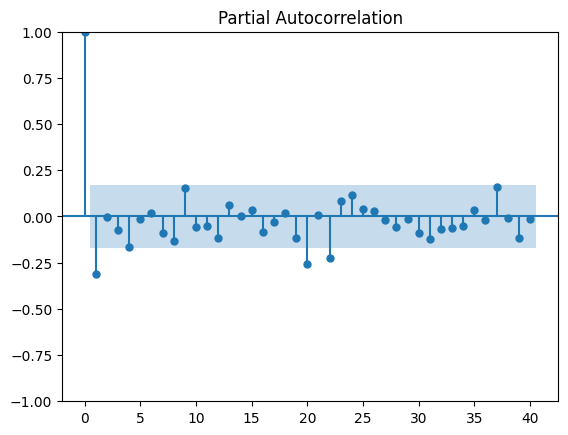

In [ ]:
plot_pacf(
    stationary_series,
    lags=40,
    method="ywm"
)
plt.show()


In [ ]:
model=SARIMAX(
    ts,
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)
results=model.fit()
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                  144
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -506.149
Date:                            Fri, 26 Jun 2026   AIC                           1022.299
Time:                                    11:56:53   BIC                           1036.675
Sample:                                01-01-1949   HQIC                          1028.140
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1272      0.356     -0.358      0.721      -0.825       0.570
ma.L1         -0.2148      0.325   

In [ ]:
print("\nAIC:", results.aic)
print("BIC:", results.bic)


AIC: 1022.2987919398666
BIC: 1036.6747785558723


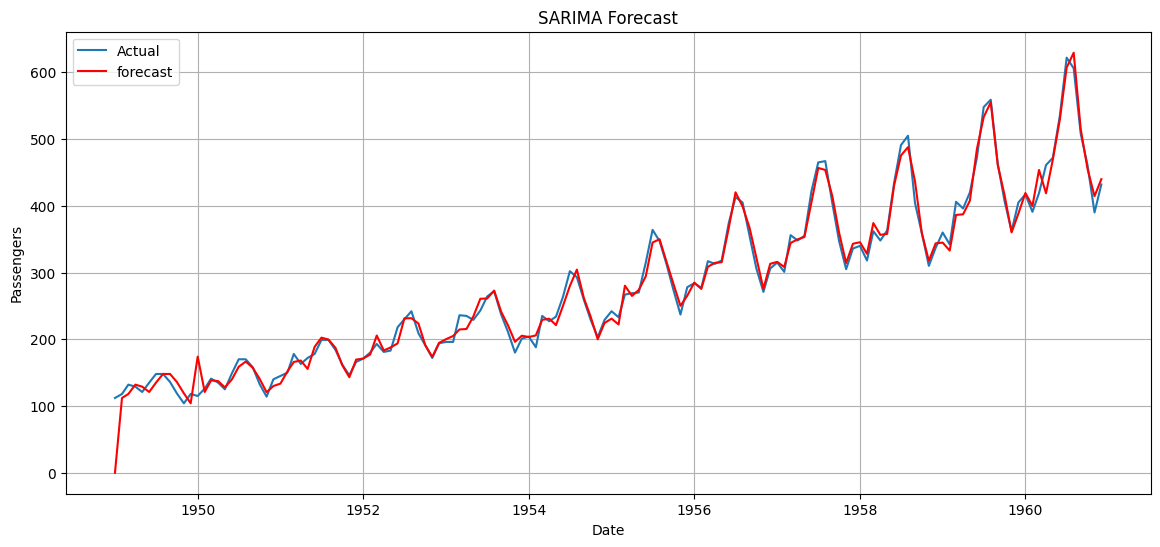

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(
    ts,
    label="Actual"
)

# Generate forecasts from the fitted model
forecast = results.predict(start=ts.index[0], end=ts.index[-1])

plt.plot(
    forecast,
    color="red",
    label="forecast"
)

plt.title("SARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()